# Assignment No. 2

## Bank Customer Churn Prediction Using Artificial Neural Network

## Import Required Libraries

The required Python libraries are imported for data handling, visualization, preprocessing, and building the Artificial Neural Network.

- **Pandas** is used to read and manipulate the dataset.
- **NumPy** is used for numerical operations.
- **Matplotlib** and **Seaborn** are used for visualization.
- **TensorFlow/Keras** is used to create and train the neural network.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

## Load the Dataset

The `read_csv()` function is used to load the Bank Customer Churn dataset from a CSV file into a Pandas DataFrame.

The `head()` function displays the first five rows of the dataset to understand its structure and contents.

In [2]:
df = pd.read_csv(r"C:\Users\rushi\Downloads\archive\Churn_Modelling.csv")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## Explore the Dataset

The `info()` function displays information about the dataset, including the number of rows, columns, column names, data types, and non-null values.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


## Check for Missing Values

The `isnull()` function identifies missing values in the dataset, while `sum()` counts the number of missing values in each column.

This helps to check whether any data cleaning is required before building the model.

In [5]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

## Remove Unnecessary Columns

The `drop()` function removes columns that are not useful for predicting customer churn.

`RowNumber`, `CustomerId`, and `Surname` are removed because they are identification or name-related fields and are not required as prediction features.

In [6]:
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)

## Convert Categorical Data into Numerical Data

The `get_dummies()` function converts categorical columns into numerical columns using one-hot encoding.

`Geography` and `Gender` are converted into numerical values so that they can be used as inputs to the neural network.

`drop_first=True` removes one category from each encoded feature to avoid unnecessary redundancy.

In [7]:
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)

In [8]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


## Separate Input and Target Variables

The dataset is divided into input features (`X`) and the target variable (`y`).

`X` contains the customer information used for prediction, while `y` contains the `Exited` column, which indicates whether the customer left the bank.

In [9]:
X = df.drop('Exited', axis=1)
y = df['Exited']

In [10]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,False,True,False


In [11]:
y.head()

0    1
1    0
2    1
3    0
4    0
Name: Exited, dtype: int64

## Split the Dataset

The `train_test_split()` function divides the dataset into training and testing data.

80% of the data is used to train the model and 20% is used to evaluate its performance.

`random_state=42` ensures that the same split is obtained each time the code is executed.

In [12]:
from sklearn.model_selection import train_test_split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

## Normalize the Features

`StandardScaler` is used to standardize the input features.

It transforms the features so that they have a similar scale, which helps the neural network learn more effectively.

The scaler is fitted only on the training data and then applied to both training and testing data.

In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [15]:
X_train = scaler.fit_transform(X_train)

In [16]:
X_test = scaler.transform(X_test)

## Create the Artificial Neural Network

A Sequential neural network is created using Keras.

The network contains:
- An input layer that accepts the dataset features.
- A hidden layer with 16 neurons using the ReLU activation function.
- A second hidden layer with 8 neurons using ReLU.
- An output layer with 1 neuron using the Sigmoid activation function.

The sigmoid output gives the probability of the customer leaving the bank.

In [17]:
model = Sequential()

model.add(Input(shape=(X_train.shape[1],)))
model.add(Dense(16, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

## Display the ANN Architecture

The `summary()` function displays the structure of the neural network, including its layers, number of neurons, and trainable parameters.

In [18]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

## Compile the Neural Network

The `compile()` function configures the neural network before training.

- **Adam** is used as the optimizer to update the model weights.
- **Binary cross-entropy** is used as the loss function because this is a binary classification problem.
- **Accuracy** is used to measure the model's prediction performance.

In [19]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Train the Neural Network

The `fit()` function trains the neural network using the training data.

The model is trained for 50 epochs with a batch size of 32.

20% of the training data is used as validation data to monitor the model's performance during training.

In [20]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7798 - loss: 0.5418 - val_accuracy: 0.8150 - val_loss: 0.4657
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8094 - loss: 0.4497 - val_accuracy: 0.8206 - val_loss: 0.4286
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8155 - loss: 0.4286 - val_accuracy: 0.8275 - val_loss: 0.4170
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8213 - loss: 0.4173 - val_accuracy: 0.8294 - val_loss: 0.4087
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8236 - loss: 0.4073 - val_accuracy: 0.8331 - val_loss: 0.3976
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8308 - loss: 0.3947 - val_accuracy: 0.8462 - val_loss: 0.3854
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8409 - loss: 0.3808 - val_accuracy: 0.8494 - val_loss: 0.3725
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8516 - loss: 0.3677 - val_accuracy: 0.

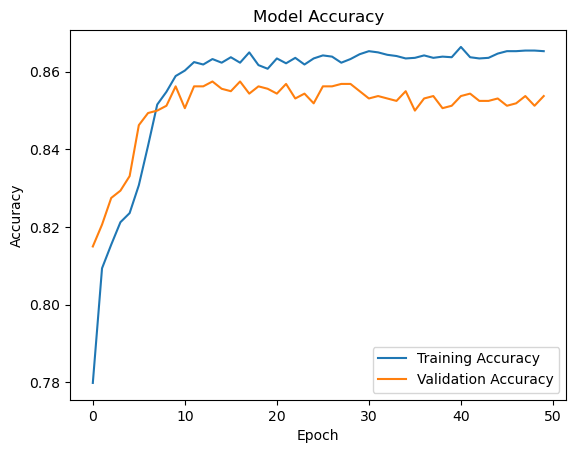

In [21]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(['Training Accuracy', 'Validation Accuracy'])
plt.show()

## Make Predictions

The `predict()` function generates prediction probabilities for the test data.

A probability greater than 0.5 is classified as `1` (customer leaves), while a probability of 0.5 or below is classified as `0` (customer stays).

The `ravel()` function converts the prediction array into a one-dimensional format.

In [22]:
y_pred_prob = model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

y_pred = y_pred.ravel()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  


## Calculate Accuracy

The `accuracy_score()` function compares the actual test values with the predicted values.

It calculates the percentage of test samples that were classified correctly by the neural network.

In [23]:
from sklearn.metrics import accuracy_score

In [24]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8575


## Generate Confusion Matrix

The `confusion_matrix()` function compares the actual and predicted classes.

It shows the number of:
- True Negatives
- False Positives
- False Negatives
- True Positives

In [25]:
from sklearn.metrics import confusion_matrix

In [26]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1531   76]
 [ 209  184]]


## Visualize the Confusion Matrix

A Seaborn heatmap is used to display the confusion matrix visually.

The values in each cell show how many customers were correctly or incorrectly classified by the model.

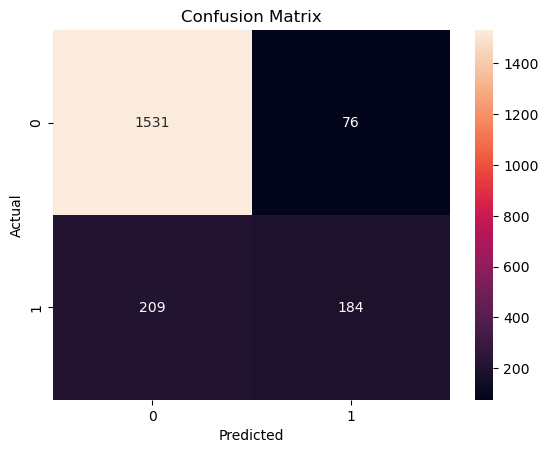

In [27]:
sns.heatmap(cm, annot=True, fmt='d')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

## Classification Report

The `classification_report()` function provides detailed performance measures for each class.

It displays:
- **Precision** – how many predicted cases were actually correct.
- **Recall** – how many actual cases were correctly identified.
- **F1-score** – the combined measure of precision and recall.
- **Support** – the number of actual samples in each class.

In [28]:
from sklearn.metrics import classification_report

In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.95      0.91      1607
           1       0.71      0.47      0.56       393

    accuracy                           0.86      2000
   macro avg       0.79      0.71      0.74      2000
weighted avg       0.85      0.86      0.85      2000

